## Load the saved experiment
This loads the provisional Data Lead export and saved models. The checks tie the model to its input and the scoring code. Choose is the only period used for performance in this notebook.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src import backtest, contract, features, modeling, nightly
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
bundle = backtest.load_bundle(backtest.BIN1_MODEL)
assert bundle["provisional"]
assert bundle["data_sha256"] == backtest.clean_data.fingerprint(backtest.BIN1_INPUT)
assert bundle["contract_sha256"] == backtest.clean_data.fingerprint(Path(contract.__file__))
assert bundle["implementation_sha256"] == backtest.implementation_hashes()
bookings = backtest.load_scoring(backtest.BIN1_INPUT, provisional_bin1=True)
_, choose, _ = contract.split_periods(bookings)
winner = bundle["selected"]
print("Choose rows:", len(choose), "Winner:", winner, "Buffer:", bundle["buffers"][winner])
print("Inputs:", ", ".join(bundle["features"]))

Choose rows: 29107 Winner: logistic Buffer: 6
Inputs: hotel, distribution_channel, is_repeated_guest, previous_cancellations, previous_bookings_not_canceled


## Predict five real bookings
We pass only the five predictor columns into the model. After that, we display the real outcome to check the example. The row number identifies the row within the handover CSV, counting from 1 and excluding the header.

In [2]:
sample = choose.iloc[[0, len(choose)//4, len(choose)//2, 3*len(choose)//4, len(choose)-1]]
sample_report = features.predictors(sample)
sample_report.insert(0, "handover_row", sample.index + 1)
sample_report["probability"] = modeling.predict(winner, bundle["models"][winner], features.predictors(sample))
sample_report["actual_outcome"] = sample["is_canceled"]
print(sample_report.to_string(index=False, float_format="{:.4f}".format))

 handover_row        hotel distribution_channel  is_repeated_guest  previous_cancellations  previous_bookings_not_canceled  probability  actual_outcome
         6618 Resort Hotel                TA/TO             0.0000                  0.0000                          0.0000       0.2572               1
        29108 Resort Hotel                TA/TO             0.0000                  0.0000                          0.0000       0.2572               0
        58284   City Hotel                TA/TO             0.0000                  0.0000                          0.0000       0.3486               1
        94865   City Hotel                TA/TO             0.0000                  0.0000                          0.0000       0.3486               0
       102444   City Hotel                TA/TO             0.0000                  0.0000                          0.0000       0.3486               0


## Measure classification at 0.50
A chance of 0.50 or higher is called a cancellation for this diagnostic. Accuracy is the fraction of all guesses right. Precision asks how often a cancellation guess was right. Recall asks how many real cancellations were found. F1 combines precision and recall. AUC measures risk ranking across thresholds. The room rule uses the original probabilities.

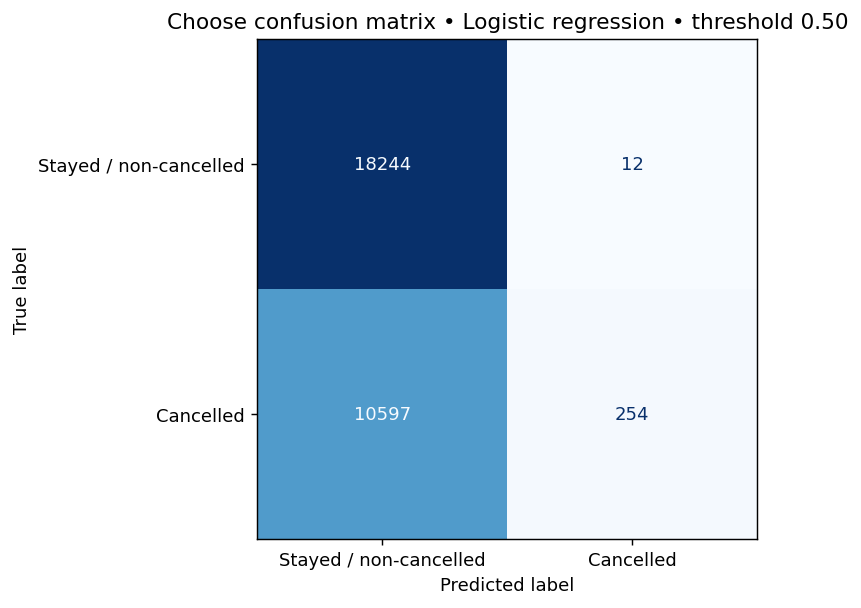

          accuracy  precision  recall     f1    auc  nightly_mae  buffer     cost_eur  empty_rooms  walked_guests  walks_per_1000  ceiling_met  nights
method                                                                                                                                                
flat        0.6272     0.0000  0.0000 0.0000 0.5573       9.1090      16 2424573.5800         5472            180          9.8600         True     368
lookup      0.6272     0.0000  0.0000 0.0000 0.6039       8.7434      16 2412360.8500         5447            181          9.9100         True     368
logistic    0.6355     0.9549  0.0234 0.0457 0.6164       9.3023       6 1968070.4000         4632            175          9.5900         True     368
forest      0.6354     0.9799  0.0225 0.0440 0.6124       9.2609       7 2080298.3400         4879            159          8.7100         True     368
Confusion matrices: rows = actual, columns = predicted, labels = [0, 1]
flat [[18256, 0], [108

In [3]:
target = choose["is_canceled"]
inputs = features.predictors(choose)
records = []
confusions = {}
night_tables = {}
for method in modeling.METHODS:
    probabilities = modeling.predict(method, bundle["models"][method], inputs)
    assert len(probabilities) == len(choose)
    labels = probabilities >= 0.50
    matrix = confusion_matrix(target, labels, labels=[0, 1])
    confusions[method] = matrix
    nights = contract.nightly_table(choose, probabilities)
    night_tables[method] = nights
    score = backtest.score_buffer(nights, bundle["buffers"][method])
    records.append(dict(method=method, accuracy=accuracy_score(target, labels),
                        precision=precision_score(target, labels, zero_division=0),
                        recall=recall_score(target, labels, zero_division=0),
                        f1=f1_score(target, labels, zero_division=0),
                        auc=roc_auc_score(target, probabilities),
                        nightly_mae=(nights["expected"]-nights["cancelled"]).abs().mean(),
                        **score))
metrics = pd.DataFrame(records).set_index("method")
print(metrics.to_string(float_format="{:.4f}".format))
print("Confusion matrices: rows = actual, columns = predicted, labels = [0, 1]")
for method, matrix in confusions.items():
    print(method, matrix.tolist())
print("Accuracy if every booking is called non-cancelled:", (target == 0).mean())
ConfusionMatrixDisplay(confusions[winner], display_labels=["Stayed / non-cancelled", "Cancelled"]).plot(
    cmap="Blues", colorbar=False
)
plt.title("Choose confusion matrix • Logistic regression • threshold 0.50")
plt.tight_layout()
plt.show()

## Check the nightly count error
Each dot is one hotel-night. The dashed line is a perfect count estimate. The average distance measured straight up or down is nightly mean absolute error, or MAE, in rooms.

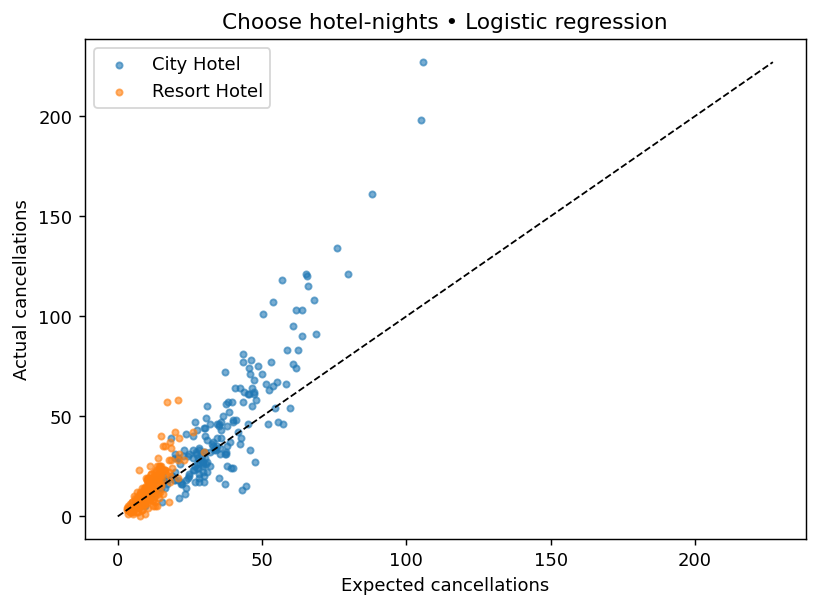

MAE: 9.3023


In [4]:
nights = night_tables[winner]
limit = max(nights["expected"].max(), nights["cancelled"].max())
for hotel, rows in nights.groupby(level="hotel"):
    plt.scatter(rows["expected"], rows["cancelled"], label=hotel, s=12, alpha=0.60)
plt.plot([0, limit], [0, limit], "k--", linewidth=1)
plt.xlabel("Expected cancellations")
plt.ylabel("Actual cancellations")
plt.title("Choose hotel-nights • Logistic regression")
plt.legend()
plt.tight_layout()
plt.show()
print("MAE:", round(metrics.loc[winner, "nightly_mae"], 4))

## Check the buffer and cost
Read the saved buffer grid. We check the chosen rule and its neighbours without choosing a new buffer. The client counts walked guests per 1,000 non-cancelled bookings and allows at most 10 across both hotels.

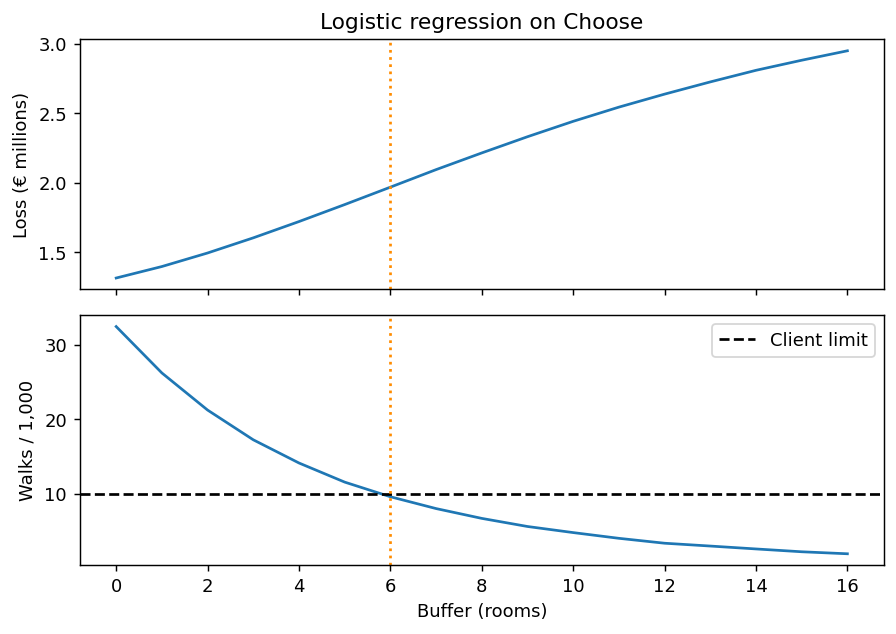

 buffer   cost_eur  empty_rooms  walked_guests  walks_per_1000  ceiling_met  nights   method
      5 1842846.16         4321            211           11.56        False     368 logistic
      6 1968070.40         4632            175            9.59         True     368 logistic
      7 2094036.03         4938            146            8.00         True     368 logistic
Pooled rate: 9.585889570552148 Allowed whole walks: 182
flat City Hotel {'buffer': 16, 'cost_eur': 1024488.15, 'empty_rooms': 2978, 'walked_guests': 178, 'walks_per_1000': 15.19, 'ceiling_met': False, 'nights': 184}
flat Resort Hotel {'buffer': 16, 'cost_eur': 1400085.43, 'empty_rooms': 2494, 'walked_guests': 2, 'walks_per_1000': 0.31, 'ceiling_met': True, 'nights': 184}
logistic City Hotel {'buffer': 6, 'cost_eur': 984823.0, 'empty_rooms': 2889, 'walked_guests': 164, 'walks_per_1000': 13.99, 'ceiling_met': False, 'nights': 184}
logistic Resort Hotel {'buffer': 6, 'cost_eur': 983247.4, 'empty_rooms': 1743, 'walked_guests

In [5]:
grid = pd.read_csv(backtest.BIN1_RESULTS / "choose_buffer_grid.csv")
near = grid.loc[grid["method"].eq(winner) & grid["buffer"].between(0, 16)]
fig, (loss, rate) = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
loss.plot(near["buffer"], near["cost_eur"] / 1_000_000)
loss.set(ylabel="Loss (€ millions)", title="Logistic regression on Choose")
rate.plot(near["buffer"], near["walks_per_1000"])
rate.axhline(contract.WALK_CEILING, linestyle="--", color="black", label="Client limit")
rate.set(xlabel="Buffer (rooms)", ylabel="Walks / 1,000")
rate.legend()
for ax in (loss, rate):
    ax.axvline(bundle["buffers"][winner], linestyle=":", color="darkorange")
fig.tight_layout()
plt.show()
print(near.loc[near["buffer"].between(5, 7)].to_string(index=False))
arrivals = int((target == 0).sum())
walks = metrics.loc[winner, "walked_guests"]
print("Pooled rate:", 1000 * walks / arrivals, "Allowed whole walks:", arrivals // 100)
for method in ("flat", winner):
    probabilities = modeling.predict(method, bundle["models"][method], inputs)
    for hotel, rows in choose.groupby("hotel"):
        mask = choose["hotel"].eq(hotel).to_numpy()
        result = backtest.score_buffer(contract.nightly_table(rows, probabilities[mask]), bundle["buffers"][method])
        print(method, hotel, result)

## Check the 14-night recommendations
The saved bundle is reloaded and predicts the same rows again. The nightly function gets only arrival fields and approved inputs, so it cannot see actual cancellations. We compare the replay to the existing CSV. This is a classroom final-list demo.

In [6]:
again = backtest.load_bundle(backtest.BIN1_MODEL)
for method in modeling.METHODS:
    np.testing.assert_array_equal(
        modeling.predict(method, bundle["models"][method], inputs),
        modeling.predict(method, again["models"][method], inputs),
    )
roster = backtest.read_bookings(backtest.BIN1_INPUT, usecols=nightly.INPUT_COLUMNS.__contains__)
assert "is_canceled" not in roster
first = nightly.nightly_recommendations(roster, "2017-08-18", 14, bundle)
second = nightly.nightly_recommendations(roster, "2017-08-18", 14, again)
pd.testing.assert_frame_equal(first, second, check_exact=True)
saved = pd.read_csv(backtest.BIN1_RESULTS / "nightly_recommendations.csv", parse_dates=["arrival_date"])
pd.testing.assert_frame_equal(first, saved, check_exact=False, rtol=0, atol=5.1e-11)
assert first.groupby("hotel")["arrival_date"].nunique().eq(14).all() and len(first) == 28
assert first["recommended_oversell"].dtype.kind in "iu" and first["recommended_oversell"].ge(0).all()
assert np.isfinite(first["expected_cancellations"]).all()
assert first["safety_buffer"].eq(bundle["buffers"][winner]).all()
print(first.to_string(index=False, float_format="{:.4f}".format))

       hotel arrival_date  bookings  expected_cancellations  safety_buffer  recommended_oversell
  City Hotel   2017-08-18       121                 39.3612              6                    33
Resort Hotel   2017-08-18        60                 13.3673              6                     7
  City Hotel   2017-08-19       122                 40.4941              6                    34
Resort Hotel   2017-08-19        66                 15.0550              6                     9
  City Hotel   2017-08-20       101                 33.1736              6                    27
Resort Hotel   2017-08-20        56                 13.1686              6                     7
  City Hotel   2017-08-21        94                 30.4267              6                    24
Resort Hotel   2017-08-21        65                 15.4664              6                     9
  City Hotel   2017-08-22        59                 18.5696              6                    12
Resort Hotel   2017-08-22     